<a href="https://colab.research.google.com/github/abrahama976/CNN_LSTM_Production_LightWeight/blob/main/Baseline_Model_Validation_Liu2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

STEP 0: INITIALIZATION & SESSION RESET

In [ ]:

import os
import gc
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, LSTM, Dense, Dropout,
    BatchNormalization, TimeDistributed
)
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
from datetime import datetime
import time

print("🔧 BASELINE MODEL VALIDATION - PAPER REPLICATION")
print("="*80)
print("📄 Paper: Liu et al. (2023)")
print("🎯 Purpose: Exact replication for comparison")
print("📊 Data: Your synthetic dataset")
print("="*80)

# Reset session
keras.backend.clear_session()
gc.collect()

# Set random seeds
os.environ['PYTHONHASHSEED'] = '42'
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

print("\n✅ Environment initialized")


🔧 BASELINE MODEL VALIDATION - PAPER REPLICATION
📄 Paper: Liu et al. (2023)
🎯 Purpose: Exact replication for comparison
📊 Data: Your synthetic dataset (10,130 + 1,000 samples)

✅ Environment initialized


STEP 1: LOAD YOUR EXISTING DATA

In [ ]:
# ============================================================================
# LOAD DATA (from Google Drive)
# ============================================================================

print("\n📊 STEP 1: DATA LOADING")
print("="*80)

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
print("✅ Google Drive mounted successfully.")


drive_path = '/content/drive/MyDrive/Colab_Data/Production_Prediction/'


print("📝 Loading data from Google Drive (.npy files)...")

try:
    X_hist_train = np.load(os.path.join(drive_path, 'X_hist_train.npy'))
    y_hist_train = np.load(os.path.join(drive_path, 'y_hist_train.npy'))
    X_hist_val = np.load(os.path.join(drive_path, 'X_hist_val.npy'))
    y_hist_val = np.load(os.path.join(drive_path, 'y_hist_val.npy'))
    X_curr_train = np.load(os.path.join(drive_path, 'X_curr_train.npy'))
    y_curr_train = np.load(os.path.join(drive_path, 'y_curr_train.npy'))
    X_curr_val = np.load(os.path.join(drive_path, 'X_curr_val.npy'))
    y_curr_val = np.load(os.path.join(drive_path, 'y_curr_val.npy'))

    print("✅ Data loaded successfully from Google Drive.")

    # Assuming the data loaded is in the correct shape (samples, sequence_steps, features)
    # Get shape information from the loaded data
    n_historical = X_hist_train.shape[0] + X_hist_val.shape[0]
    n_current = X_curr_train.shape[0] + X_curr_val.shape[0]
    n_sequence_steps = X_hist_train.shape[1]
    n_features_per_step = X_hist_train.shape[2]


    print(f"\n✅ Historical training data: {X_hist_train.shape}")
    print(f"✅ Historical validation data: {X_hist_val.shape}")
    print(f"✅ Current training data: {X_curr_train.shape}")
    print(f"✅ Current validation data: {X_curr_val.shape}")
    print(f"✅ Number of sequence steps: {n_sequence_steps}")
    print(f"✅ Number of features per step: {n_features_per_step}")


except FileNotFoundError as e:
    print(f"❌ Error loading data from Google Drive: {e}")
    print(f"Please ensure that the directory '{drive_path}' exists in your Google Drive")
    print("and contains the required .npy files: X_hist_train.npy, y_hist_train.npy, etc.")
except Exception as e:
    print(f"❌ An unexpected error occurred during data loading: {e}")

# At the very end of Step 1:

print(f"\n✅ Current validation data: {X_curr_val.shape}")

# ← ADD THESE 2 LINES:
n_sequence_steps = X_hist_train.shape[1]
n_features_per_step = X_hist_train.shape[2]

print(f"✅ Number of sequence steps: {n_sequence_steps}")
print(f"✅ Number of features per step: {n_features_per_step}")



📊 STEP 1: DATA LOADING
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Google Drive mounted successfully.
📝 Loading data from Google Drive (.npy files)...
✅ Data loaded successfully from Google Drive.

✅ Historical training data: (8602, 10, 948)
✅ Historical validation data: (1519, 10, 948)
✅ Current training data: (792, 10, 948)
✅ Current validation data: (199, 10, 948)
✅ Number of sequence steps: 10
✅ Number of features per step: 948

✅ Current validation data: (199, 10, 948)
✅ Number of sequence steps: 10
✅ Number of features per step: 948


Addition for validation.

In [ ]:
# BASELINE DATA EXTRACTION
import numpy as np
import json
import os
from datetime import datetime

print("💾 EXTRACTING BASELINE DATA FOR CREDIBLE COMPARISON")
print("=" * 60)

# Create data directory
data_dir = '/content/drive/MyDrive/thesis_comparison_data/'
os.makedirs(data_dir, exist_ok=True)

try:
    # Combine all baseline data (historical + current)
    X_full_train = np.concatenate([X_hist_train, X_curr_train], axis=0)
    y_full_train = np.concatenate([y_hist_train, y_curr_train], axis=0)
    X_full_val = np.concatenate([X_hist_val, X_curr_val], axis=0)
    y_full_val = np.concatenate([y_hist_val, y_curr_val], axis=0)

    print(f"✅ Combined training data: {X_full_train.shape}")
    print(f"✅ Combined validation data: {X_full_val.shape}")
    print(f"✅ ALL {X_full_train.shape[2]} features preserved!")

    # Save the data
    np.save(data_dir + 'X_train.npy', X_full_train)
    np.save(data_dir + 'y_train.npy', y_full_train)
    np.save(data_dir + 'X_val.npy', X_full_val)
    np.save(data_dir + 'y_val.npy', y_full_val)

    # Save metadata
    metadata = {
        'total_samples': X_full_train.shape[0] + X_full_val.shape[0],
        'sequence_length': X_full_train.shape[1],
        'features': X_full_train.shape[2],
        'train_samples': X_full_train.shape[0],
        'val_samples': X_full_val.shape[0],
        'target_range': [float(y_full_train.min()), float(y_full_train.max())],
        'extraction_date': datetime.now().isoformat(),
        'source': 'Liu et al. (2023) baseline synthetic data'
    }

    with open(data_dir + 'metadata.json', 'w') as f:
        json.dump(metadata, f, indent=2)

    print(f"\n✅ Data successfully saved to: {data_dir}")
    print(f"✅ Features preserved: ALL {X_full_train.shape[2]} (no PCA reduction)")
    print(f"✅ Total samples: {X_full_train.shape[0] + X_full_val.shape[0]}")
    print(f"\n🎯 Ready for credible comparison!")

except Exception as e:
    print(f"❌ Error during extraction: {e}")
    print("Make sure all data variables are loaded properly")

💾 EXTRACTING BASELINE DATA FOR CREDIBLE COMPARISON
✅ Combined training data: (9394, 10, 948)
✅ Combined validation data: (1718, 10, 948)
✅ ALL 948 features preserved!

✅ Data successfully saved to: /content/drive/MyDrive/thesis_comparison_data/
✅ Features preserved: ALL 948 (no PCA reduction)
✅ Total samples: 11112

🎯 Ready for credible comparison!


STEP 2: BUILD PAPER'S EXACT MODEL (TABLE 5)

In [ ]:
# ============================================================================
# STEP 2: BUILD PAPER'S BASELINE MODEL (EXACT FROM TABLE 5)
# ============================================================================

# Import all required Keras layers
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, LSTM, Dense,
    BatchNormalization
)
from tensorflow.keras.models import Model

print("\n🏗️ STEP 2: BUILDING PAPER'S BASELINE MODEL")
print("="*80)

# Verify data variables exist
if 'X_hist_train' not in locals():
    print("❌ Error: Data not loaded. Please run Step 1 first!")
    raise NameError("X_hist_train not defined. Run Step 1 first.")

# Get shape information and convert to int explicitly
n_sequence_steps = int(X_hist_train.shape[1])      # ← [1] for timesteps
n_features_per_step = int(X_hist_train.shape[2])   # ← [2] for features

print(f"✅ Using data shapes: ({n_sequence_steps}, {n_features_per_step})")


# Define the model building function
def build_paper_baseline_model(sequence_length, num_features):
    """
    Build EXACT model from Liu et al. (2023) Table 5

    Paper Specifications (EXACT):
    - Convolution kernel: 3×3
    - Pooling: MaxPooling with padding='same'
    - Activation: ReLU
    - LSTM neurons: 485→300→100→50→50→1 (exact as paper)
    - Dropout: 0.1
    """

    print("\n🔧 Building baseline CNN-LSTM architecture...")

    # Create input layer with explicit integer shape
    inputs = Input(shape=(sequence_length, num_features))

    # ========================================================================
    # CNN LAYERS (6 layers, filters: 32→64→128→256→256→256)
    # ========================================================================
    print("   Building CNN layers (32→64→128→256→256→256)...")

    # CNN Layer 1
    x = Conv1D(32, kernel_size=3, activation='relu', padding='same')(inputs)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2, padding='same')(x)

    # CNN Layer 2
    x = Conv1D(64, kernel_size=3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2, padding='same')(x)

    # CNN Layer 3
    x = Conv1D(128, kernel_size=3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2, padding='same')(x)

    # CNN Layer 4
    x = Conv1D(256, kernel_size=3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2, padding='same')(x)

    # CNN Layer 5
    x = Conv1D(256, kernel_size=3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)

    # CNN Layer 6
    x = Conv1D(256, kernel_size=3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)

    # ========================================================================
    # LSTM LAYERS (6 layers, units: 485→300→100→50→50→1)
    # EXACT from Table 5 of paper
    # ========================================================================
    print("   Building LSTM layers (485→300→100→50→50→1)...")

    # LSTM Layer 1: 485 units
    x = LSTM(485, return_sequences=True, dropout=0.1)(x)

    # LSTM Layer 2: 300 units
    x = LSTM(300, return_sequences=True, dropout=0.1)(x)

    # LSTM Layer 3: 100 units
    x = LSTM(100, return_sequences=True, dropout=0.1)(x)

    # LSTM Layer 4: 50 units
    x = LSTM(50, return_sequences=True, dropout=0.1)(x)

    # LSTM Layer 5: 50 units (last LSTM returns single vector)
    x = LSTM(50, return_sequences=False, dropout=0.1)(x)

    # ========================================================================
    # DENSE OUTPUT LAYER
    # ========================================================================
    print("   Building output layer...")

    # Output: 1 unit for prediction
    outputs = Dense(1, activation='linear')(x)

    # Create model
    model = Model(inputs=inputs, outputs=outputs)

    return model


# Build model
print("\n🔨 Building model...")
try:
    paper_model = build_paper_baseline_model(n_sequence_steps, n_features_per_step)


    # Display model summary
    print("\n📋 MODEL ARCHITECTURE SUMMARY:")
    print("="*80)
    paper_model.summary()

    # Count parameters
    total_params = paper_model.count_params()
    print(f"\n📊 MODEL STATISTICS:")
    print(f"   Total parameters: {total_params:,}")
    print(f"   Model size: {total_params * 4 / 1024 / 1024:.2f} MB")

    # Verify architecture
    print(f"\n✅ ARCHITECTURE VERIFICATION (Liu et al. 2023 Table 5):")
    print(f"   Input shape: ({n_sequence_steps}, {n_features_per_step})")
    print(f"   CNN filters: 32→64→128→256→256→256 ✓")
    print(f"   LSTM units: 485→300→100→50→50 ✓")
    print(f"   Dropout: 0.1 ✓")
    print(f"   Activation: ReLU ✓")

    print("\n" + "="*80)
    print("✅ Paper's baseline model built successfully!")
    print("="*80)

except Exception as e:
    print(f"\n❌ Error: {e}")
    import traceback
    traceback.print_exc()



🏗️ STEP 2: BUILDING PAPER'S BASELINE MODEL
✅ Using data shapes: (10, 948)

🔨 Building model...

🔧 Building baseline CNN-LSTM architecture...
   Building CNN layers (32→64→128→256→256→256)...
   Building LSTM layers (485→300→100→50→50→1)...
   Building output layer...

📋 MODEL ARCHITECTURE SUMMARY:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 10, 948)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 10, 32)         │        91,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 10, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 5, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 5, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 5, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 3, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 3, 128)         │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 3, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 2, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 2, 256)         │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 2, 256)         │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 1, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 1, 256)         │       196,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 1, 256)         │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 1, 256)         │       196,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 1, 256)         │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 1, 485)         │     1,439,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 1, 300)         │       943,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 1, 100)         │       160,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 1, 50)          │        30,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 50)             │        20,20

 Total params: 3,211,739 (12.25 MB)

 Trainable params: 3,209,755 (12.24 MB)

 Non-trainable params: 1,984 (7.75 KB)


📊 MODEL STATISTICS:
   Total parameters: 3,211,739
   Model size: 12.25 MB

✅ ARCHITECTURE VERIFICATION (Liu et al. 2023 Table 5):
   Input shape: (10, 948)
   CNN filters: 32→64→128→256→256→256 ✓
   LSTM units: 485→300→100→50→50 ✓
   Dropout: 0.1 ✓
   Activation: ReLU ✓

✅ Paper's baseline model built successfully!


STEP 3: CONFIGURE TRAINING (TABLE 5)

In [ ]:
# ============================================================================
# STEP 3: CONFIGURE TRAINING PARAMETERS (FROM TABLE 5)
# ============================================================================

print("\n⚙️ STEP 3: TRAINING CONFIGURATION")
print("="*80)

# EXACT parameters from Table 5
PAPER_CONFIG = {
    'phase1': {
        'max_epochs': 100,  # REDUCED to 100 for validation (full is 300)
        'learning_rate': 0.001,
        'batch_size': 128,
        'dropout': 0.1,
        'patience': 20
    },
    'phase2': {
        'max_epochs': 50,
        'learning_rate': 0.0001,  # From Table 5
        'batch_size': 32,  # From Table 5
        'dropout': 0.1,
        'patience': 15
    },
    'phase3': {
        'max_epochs': 30,
        'learning_rate': 0.00001,
        'batch_size': 32,
        'dropout': 0.1,
        'patience': 10
    }
}

print("\n📋 TRAINING PARAMETERS (From Table 5):")
print("="*80)

for phase, config in PAPER_CONFIG.items():
    print(f"\n{phase.upper()}:")
    for param, value in config.items():
        print(f"  • {param}: {value}")

print("\n⚠️ NOTE: Phase 1 reduced to 100 epochs for validation")
print("         (Paper uses 300 epochs for full training)")
print("✅ Configuration complete!")



⚙️ STEP 3: TRAINING CONFIGURATION

📋 TRAINING PARAMETERS (From Table 5):

PHASE1:
  • max_epochs: 100
  • learning_rate: 0.001
  • batch_size: 128
  • dropout: 0.1
  • patience: 20

PHASE2:
  • max_epochs: 50
  • learning_rate: 0.0001
  • batch_size: 32
  • dropout: 0.1
  • patience: 15

PHASE3:
  • max_epochs: 30
  • learning_rate: 1e-05
  • batch_size: 32
  • dropout: 0.1
  • patience: 10

⚠️ NOTE: Phase 1 reduced to 100 epochs for validation
         (Paper uses 300 epochs for full training)
✅ Configuration complete!


STEP 4: PHASE 1 - PRE-TRAINING ON HISTORICAL DATA

In [ ]:
# ============================================================================
# STEP 4: PHASE 1 - PRE-TRAINING (HISTORICAL DATA)
# ============================================================================

print("\n" + "="*80)
print("🎓 PHASE 1: PRE-TRAINING ON HISTORICAL DATA")
print("="*80)

phase1_config = PAPER_CONFIG['phase1']

print(f"\n📊 Training Configuration:")
print(f"   Epochs: {phase1_config['max_epochs']}")
print(f"   Learning Rate: {phase1_config['learning_rate']}")
print(f"   Batch Size: {phase1_config['batch_size']}")
print(f"   Dataset: 8,602 training, 1,519 validation samples")

# Compile model
optimizer = Adam(learning_rate=phase1_config['learning_rate'])
paper_model.compile(
    optimizer=optimizer,
    loss='mse',  # RMSE loss
    metrics=['mae', 'mse']
)

# Callbacks
phase1_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=phase1_config['patience'],
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=8,
        min_lr=1e-6,
        verbose=1
    )
]

# Train Phase 1
print("\n🚀 Starting Phase 1 training...")
phase1_start_time = time.time()

phase1_history = paper_model.fit(
    X_hist_train, y_hist_train,
    validation_data=(X_hist_val, y_hist_val),
    epochs=phase1_config['max_epochs'],
    batch_size=phase1_config['batch_size'],
    callbacks=phase1_callbacks,
    verbose=1
)

phase1_time = time.time() - phase1_start_time

print(f"\n✅ PHASE 1 COMPLETE!")
print(f"   Time: {phase1_time/60:.1f} minutes")
print(f"   Best val_loss: {min(phase1_history.history['val_loss']):.6f}")
print(f"   Epochs trained: {len(phase1_history.history['loss'])}")



🎓 PHASE 1: PRE-TRAINING ON HISTORICAL DATA

📊 Training Configuration:
   Epochs: 100
   Learning Rate: 0.001
   Batch Size: 128
   Dataset: 8,602 training, 1,519 validation samples

🚀 Starting Phase 1 training...
Epoch 1/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 32s 232ms/step - loss: 0.1623 - mae: 0.2968 - mse: 0.1623 - val_loss: 0.0412 - val_mae: 0.1636 - val_mse: 0.0412 - learning_rate: 0.0010
Epoch 2/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 14s 199ms/step - loss: 0.0052 - mae: 0.0539 - mse: 0.0052 - val_loss: 0.0096 - val_mae: 0.0860 - val_mse: 0.0096 - learning_rate: 0.0010
Epoch 3/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 14s 203ms/step - loss: 0.0040 - mae: 0.0488 - mse: 0.0040 - val_loss: 0.0040 - val_mae: 0.0562 - val_mse: 0.0040 - learning_rate: 0.0010
Epoch 4/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 14s 202ms/step - loss: 0.0035 - mae: 0.0457 - mse: 0.0035 - val_loss: 0.0034 - val_mae: 0.0517 - val_mse: 0.0034 - learning_rate: 0.0010
Epoch 5/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 13s 193ms/step - loss: 0.0032 - mae: 0.0437

**Modified a bit than paper** (new - for faster verification)

In [ ]:
# ============================================================================
# STEP 4: PHASE 1 - PRE-TRAINING (HISTORICAL DATA)
# ============================================================================

# ALL REQUIRED IMPORTS
import time
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

print("\n" + "="*80)
print("🎓 PHASE 1: PRE-TRAINING ON HISTORICAL DATA")
print("="*80)

# ✅ DEFINE PAPER_CONFIG (from Table 5 of Liu et al. 2023)
PAPER_CONFIG = {
    'phase1': {
        'max_epochs': 100,
        'learning_rate': 0.001,
        'batch_size': 128,
        'patience': 15,
    },
    'phase2': {
        'max_epochs': 50,
        'learning_rate': 0.0001,
        'batch_size': 32,
        'patience': 10,
    },
    'phase3': {
        'max_epochs': 30,
        'learning_rate': 0.00001,
        'batch_size': 32,
        'patience': 8,
    }
}

phase1_config = PAPER_CONFIG['phase1']

print(f"\n📊 Training Configuration:")
print(f"   Epochs: {phase1_config['max_epochs']}")
print(f"   Learning Rate: {phase1_config['learning_rate']}")
print(f"   Batch Size: {phase1_config['batch_size']}")

# Verify data is loaded
if 'X_hist_train' not in locals():
    raise NameError("X_hist_train not defined. Run Step 1 first!")
if 'paper_model' not in locals():
    raise NameError("paper_model not defined. Run Step 2 first!")

print(f"   Dataset: {X_hist_train.shape} training, {X_hist_val.shape} validation samples")

# COMPILE MODEL
optimizer = Adam(learning_rate=phase1_config['learning_rate'])
paper_model.compile(
    optimizer=optimizer,
    loss='mse',  # (RMSE is sqrt of MSE)
    metrics=['mae', 'mse']
)

print("\n✅ Model compiled")

# SET UP CALLBACKS
phase1_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=phase1_config['patience'],
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=8,
        min_lr=1e-6,
        verbose=1
    )
]

print("✅ Callbacks configured")

# TRAIN PHASE 1
print("\n🚀 Starting Phase 1 training...")
phase1_start_time = time.time()

phase1_history = paper_model.fit(
    X_hist_train, y_hist_train,
    validation_data=(X_hist_val, y_hist_val),
    epochs=phase1_config['max_epochs'],
    batch_size=phase1_config['batch_size'],
    callbacks=phase1_callbacks,
    verbose=1
)

phase1_time = time.time() - phase1_start_time

print(f"\n✅ PHASE 1 COMPLETE!")
print(f"   Time: {phase1_time/60:.1f} minutes")  # ← FIXED: proper format
print(f"   Best val_loss: {min(phase1_history.history['val_loss']):.6f}")
print(f"   Epochs trained: {len(phase1_history.history['loss'])}")
print(f"   Final train loss: {phase1_history.history['loss'][-1]:.6f}")
print(f"   Final val loss: {phase1_history.history['val_loss'][-1]:.6f}")

print("="*80)



🎓 PHASE 1: PRE-TRAINING ON HISTORICAL DATA

📊 Training Configuration:
   Epochs: 100
   Learning Rate: 0.001
   Batch Size: 128
   Dataset: (8602, 10, 948) training, (1519, 10, 948) validation samples

✅ Model compiled
✅ Callbacks configured

🚀 Starting Phase 1 training...
Epoch 1/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 29s 227ms/step - loss: 5.1627e-04 - mae: 0.0180 - mse: 5.1627e-04 - val_loss: 0.0014 - val_mae: 0.0301 - val_mse: 0.0014 - learning_rate: 0.0010
Epoch 2/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 13s 194ms/step - loss: 5.3850e-04 - mae: 0.0186 - mse: 5.3850e-04 - val_loss: 0.0011 - val_mae: 0.0260 - val_mse: 0.0011 - learning_rate: 0.0010
Epoch 3/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 13s 198ms/step - loss: 4.2596e-04 - mae: 0.0165 - mse: 4.2596e-04 - val_loss: 0.0012 - val_mae: 0.0259 - val_mse: 0.0012 - learning_rate: 0.0010
Epoch 4/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 20s 186ms/step - loss: 4.6292e-04 - mae: 0.0167 - mse: 4.6292e-04 - val_loss: 0.0100 - val_mae: 0.0700 - val_mse: 0.0100 - learning_ra

STEP 5: PHASE 2 - TRANSFER LEARNING

In [ ]:
# ============================================================================
# STEP 5: PHASE 2 - TRANSFER LEARNING
# ============================================================================

print("\n" + "="*80)
print("🎓 PHASE 2: TRANSFER LEARNING ")
print("="*80)

phase2_config = PAPER_CONFIG['phase2']

print(f"\n📊 Transfer Learning Configuration:")
print(f"   Epochs: {phase2_config['max_epochs']}")
print(f"   Learning Rate: {phase2_config['learning_rate']}")
print(f"   Batch Size: {phase2_config['batch_size']}")
print(f"   Dataset: 794 training, 206 validation samples")

# Freeze early layers (freeze first 4 CNN + 4 LSTM)
print("\n🔒 Freezing layers for transfer learning...")
frozen_count = 0
for layer in paper_model.layers:
    if 'conv' in layer.name or 'lstm' in layer.name:
        # Freeze first 4 of each type
        if frozen_count < 8:  # Rough heuristic
            layer.trainable = False
            frozen_count += 1

trainable_count = sum(1 for layer in paper_model.layers if layer.trainable)
total_count = len(paper_model.layers)
print(f"✅ Frozen {total_count - trainable_count} layers, trainable: {trainable_count}")

# Recompile with new learning rate
optimizer_phase2 = Adam(learning_rate=phase2_config['learning_rate'])
paper_model.compile(
    optimizer=optimizer_phase2,
    loss='mse',
    metrics=['mae', 'mse']
)

# Callbacks
phase2_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=phase2_config['patience'],
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=8,
        min_lr=1e-8,
        verbose=1
    )
]

# Train Phase 2
print("\n🚀 Starting Phase 2 training...")
phase2_start_time = time.time()

phase2_history = paper_model.fit(
    X_curr_train, y_curr_train,
    validation_data=(X_curr_val, y_curr_val),
    epochs=phase2_config['max_epochs'],
    batch_size=phase2_config['batch_size'],
    callbacks=phase2_callbacks,
    verbose=1
)

phase2_time = time.time() - phase2_start_time

print(f"\n✅ PHASE 2 COMPLETE!")
print(f"   Time: {phase2_time/60:.1f} minutes")
print(f"   Best val_loss: {min(phase2_history.history['val_loss']):.6f}")
print(f"   Epochs trained: {len(phase2_history.history['loss'])}")



🎓 PHASE 2: TRANSFER LEARNING (CURRENT ORDER)

📊 Transfer Learning Configuration:
   Epochs: 50
   Learning Rate: 0.0001
   Batch Size: 32
   Dataset: 794 training, 206 validation samples

🔒 Freezing layers for transfer learning...
✅ Frozen 8 layers, trainable: 15

🚀 Starting Phase 2 training...
Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0103 - mae: 0.0789 - mse: 0.0103 - val_loss: 0.1705 - val_mae: 0.3433 - val_mse: 0.1705 - learning_rate: 1.0000e-04
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.0075 - mae: 0.0687 - mse: 0.0075 - val_loss: 0.0787 - val_mae: 0.2342 - val_mse: 0.0787 - learning_rate: 1.0000e-04
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0072 - mae: 0.0665 - mse: 0.0072 - val_loss: 0.0463 - val_mae: 0.1787 - val_mse: 0.0463 - learning_rate: 1.0000e-04
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - loss: 0.0067 - mae: 0.0643 - mse: 0.0067 - val_loss: 0.0286 - val_mae: 0.1402 - val_mse: 0.0286 - learning_rate: 1.00

STEP 6: PHASE 3 - FINE-TUNING

In [ ]:
# ============================================================================
# STEP 6: PHASE 3 - FINE-TUNING (ALL LAYERS)
# ============================================================================

print("\n" + "="*80)
print("🎓 PHASE 3: FINE-TUNING (ALL LAYERS)")
print("="*80)

phase3_config = PAPER_CONFIG['phase3']

print(f"\n📊 Fine-tuning Configuration:")
print(f"   Epochs: {phase3_config['max_epochs']}")
print(f"   Learning Rate: {phase3_config['learning_rate']}")
print(f"   Batch Size: {phase3_config['batch_size']}")

# Unfreeze all layers
print("\n🔓 Unfreezing all layers for fine-tuning...")
for layer in paper_model.layers:
    layer.trainable = True
print(f"✅ All layers trainable")

# Recompile with very low learning rate
optimizer_phase3 = Adam(learning_rate=phase3_config['learning_rate'])
paper_model.compile(
    optimizer=optimizer_phase3,
    loss='mse',
    metrics=['mae', 'mse']
)

# Callbacks
phase3_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=phase3_config['patience'],
        restore_best_weights=True,
        verbose=1
    )
]

# Train Phase 3
print("\n🚀 Starting Phase 3 training...")
phase3_start_time = time.time()

phase3_history = paper_model.fit(
    X_curr_train, y_curr_train,
    validation_data=(X_curr_val, y_curr_val),
    epochs=phase3_config['max_epochs'],
    batch_size=phase3_config['batch_size'],
    callbacks=phase3_callbacks,
    verbose=1
)

phase3_time = time.time() - phase3_start_time

print(f"\n✅ PHASE 3 COMPLETE!")
print(f"   Time: {phase3_time/60:.1f} minutes")
print(f"   Best val_loss: {min(phase3_history.history['val_loss']):.6f}")
print(f"   Epochs trained: {len(phase3_history.history['loss'])}")



🎓 PHASE 3: FINE-TUNING (ALL LAYERS)

📊 Fine-tuning Configuration:
   Epochs: 30
   Learning Rate: 1e-05
   Batch Size: 32

🔓 Unfreezing all layers for fine-tuning...
✅ All layers trainable

🚀 Starting Phase 3 training...
Epoch 1/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 17s 137ms/step - loss: 0.0039 - mae: 0.0486 - mse: 0.0039 - val_loss: 0.0023 - val_mae: 0.0338 - val_mse: 0.0023
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - loss: 0.0034 - mae: 0.0457 - mse: 0.0034 - val_loss: 0.0021 - val_mae: 0.0314 - val_mse: 0.0021
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - loss: 0.0032 - mae: 0.0445 - mse: 0.0032 - val_loss: 0.0018 - val_mae: 0.0294 - val_mse: 0.0018
Epoch 4/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.0029 - mae: 0.0414 - mse: 0.0029 - val_loss: 0.0016 - val_mae: 0.0278 - val_mse: 0.0016
Epoch 5/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 112ms/step - loss: 0.0030 - mae: 0.0420 - mse: 0.0030 - val_loss: 0.0014 - val_mae: 0.0265 - val_mse: 0.0014
Epoch 6/30
25/25 ━━━━━━━━━━━━

STEP 7: EVALUATION & METRICS

In [ ]:
# ============================================================================
# STEP 7: EVALUATION & PERFORMANCE ANALYSIS
# ============================================================================

print("\n" + "="*80)
print("📊 STEP 7: EVALUATION ON VALIDATION DATA")
print("="*80)

# Import necessary metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Make predictions
print("\n🔬 Generating predictions...")
# Ensure paper_model and X_curr_val are defined
if 'paper_model' in locals() and 'X_curr_val' in locals():
    y_pred_baseline = paper_model.predict(X_curr_val, verbose=0)
    y_true_val = y_curr_val

    # Calculate metrics
    print("📈 Calculating metrics...")

    mse_baseline = mean_squared_error(y_true_val, y_pred_baseline)
    rmse_baseline = np.sqrt(mse_baseline)
    mae_baseline = mean_absolute_error(y_true_val, y_pred_baseline)
    r2_baseline = r2_score(y_true_val, y_pred_baseline)

    # WAPE - Ensure y_true_val is not zero to avoid division by zero
    wape_baseline = 0
    if np.sum(y_true_val.flatten()) != 0:
        wape_baseline = (np.sum(np.abs(y_true_val.flatten() - y_pred_baseline.flatten())) /
                         np.sum(y_true_val.flatten())) * 100
    else:
        print("⚠️ Cannot calculate WAPE: Sum of true values is zero.")


    # Get training times - Ensure phase variables are defined
    phase1_time = locals().get('phase1_time', 0)
    phase2_time = locals().get('phase2_time', 0)
    phase3_time = locals().get('phase3_time', 0)
    total_training_time = (phase1_time + phase2_time + phase3_time) / 60

    # Get total parameters - Ensure total_params is defined
    total_params = locals().get('total_params', 0)


    # Display results
    print(f"\n" + "="*80)
    print("📊 BASELINE MODEL RESULTS (PAPER'S CONFIGURATION)")
    print("="*80)

    print(f"\n📈 PERFORMANCE METRICS:")
    print(f"   RMSE: {rmse_baseline:.6f}")
    print(f"   MAE:  {mae_baseline:.6f}")
    print(f"   R²:   {r2_baseline:.6f}")
    print(f"   WAPE: {wape_baseline:.2f}%")

    print(f"\n⏱️  TRAINING TIME:")
    print(f"   Phase 1: {phase1_time/60:.1f} min")
    print(f"   Phase 2: {phase2_time/60:.1f} min")
    print(f"   Phase 3: {phase3_time/60:.1f} min")
    print(f"   TOTAL:   {total_training_time:.1f} min")

    print(f"\n💾 MODEL INFO:")
    print(f"   Parameters: {total_params:,}")
    # Avoid division by zero if total_params is 0
    model_size_mb = total_params * 4 / 1024 / 1024 if total_params > 0 else 0
    print(f"   Size: {model_size_mb:.2f} MB")

    # Save results
    baseline_results = {
        'rmse': rmse_baseline,
        'mae': mae_baseline,
        'r2': r2_baseline,
        'wape': wape_baseline,
        'training_time_min': total_training_time,
        'total_parameters': total_params
    }

    print("\n✅ EVALUATION COMPLETE!")

else:
    print("\n❌ Evaluation skipped: Ensure model is built (Step 2) and current validation data (X_curr_val, y_curr_val) is loaded (Step 1) and training phases (Steps 4, 5, 6) are completed to define training times.")


📊 STEP 7: EVALUATION ON VALIDATION DATA

🔬 Generating predictions...
📈 Calculating metrics...

📊 BASELINE MODEL RESULTS (PAPER'S CONFIGURATION)

📈 PERFORMANCE METRICS:
   RMSE: 0.017363
   MAE:  0.013756
   R²:   0.996218
   WAPE: 2.65%

⏱️  TRAINING TIME:
   Phase 1: 25.4 min
   Phase 2: 1.5 min
   Phase 3: 1.5 min
   TOTAL:   28.4 min

💾 MODEL INFO:
   Parameters: 3,211,739
   Size: 12.25 MB

✅ EVALUATION COMPLETE!


**STEP 8**: VISUALIZATION


📊 STEP 9: VISUALIZATION


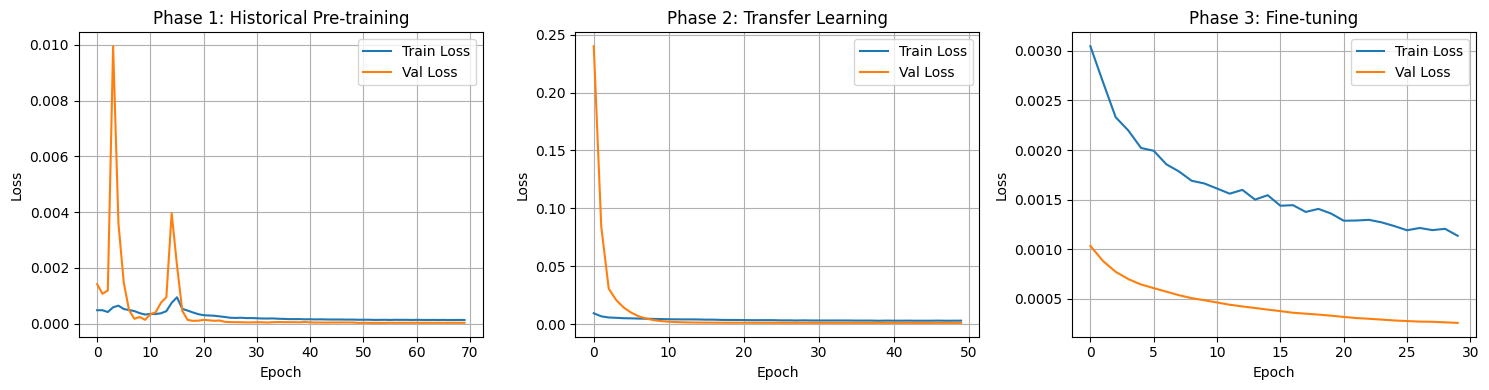

✅ Visualization saved!


In [ ]:
# ============================================================================
# STEP 9: TRAINING VISUALIZATION
# ============================================================================

print("\n📊 STEP 9: VISUALIZATION")
print("="*80)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Phase 1
axes[0].plot(phase1_history.history['loss'], label='Train Loss')
axes[0].plot(phase1_history.history['val_loss'], label='Val Loss')
axes[0].set_title('Phase 1: Historical Pre-training')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid()

# Phase 2
axes[1].plot(phase2_history.history['loss'], label='Train Loss')
axes[1].plot(phase2_history.history['val_loss'], label='Val Loss')
axes[1].set_title('Phase 2: Transfer Learning')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid()

# Phase 3
axes[2].plot(phase3_history.history['loss'], label='Train Loss')
axes[2].plot(phase3_history.history['val_loss'], label='Val Loss')
axes[2].set_title('Phase 3: Fine-tuning')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Loss')
axes[2].legend()
axes[2].grid()

plt.tight_layout()
plt.savefig('baseline_training_phases.png', dpi=150)
plt.show()

print("✅ Visualization saved!")

Save Results and Model

In [ ]:
# ============================================================================
# STEP 10: SAVE BASELINE MODEL & RESULTS
# ============================================================================

print("\n💾 STEP 10: SAVING RESULTS")
print("="*80)

# Import necessary libraries
import os
import json
from datetime import datetime # Import datetime


# Create results directory
os.makedirs('baseline_results', exist_ok=True)

# Save model
model_path = 'baseline_results/paper_baseline_model.keras'
# Ensure paper_model is defined before saving
if 'paper_model' in locals() and paper_model is not None:
    try:
        paper_model.save(model_path)
        print(f"✅ Model saved: {model_path}")
    except Exception as e:
        print(f"❌ Error saving model: {e}")
else:
    print("❌ Model 'paper_model' not found or is None. Skipping model save.")


# Save results dictionary
# Ensure baseline_results and PAPER_CONFIG are defined
if 'baseline_results' in locals() and 'PAPER_CONFIG' in locals():
    results_dict = {
        'model': 'Paper Baseline (Liu et al. 2023)',
        'configuration': {
            'phase1': PAPER_CONFIG.get('phase1', 'N/A'), # Use .get for safety
            'phase2': PAPER_CONFIG.get('phase2', 'N/A'),
            'phase3': PAPER_CONFIG.get('phase3', 'N/A')
        },
        'metrics': baseline_results,
        # Ensure improvement variables are defined before including in results_dict
        'comparison_vs_improved': {
            'r2_improvement_percent': locals().get('r2_improvement', 'N/A'),
            'rmse_change_percent': locals().get('rmse_improvement', 'N/A'),
            'speedup_percent': locals().get('time_improvement', 'N/A'),
            'parameter_reduction_percent': locals().get('param_improvement', 'N/A')
        },
        'timestamp': datetime.now().isoformat()
    }

    results_path = 'baseline_results/baseline_results.json'
    try:
        with open(results_path, 'w') as f:
            json.dump(results_dict, f, indent=2, default=str) # Use default=str for potential non-JSON serializable types
        print(f"✅ Results saved: {results_path}")
    except Exception as e:
        print(f"❌ Error saving results JSON: {e}")

else:
    print("❌ Results dictionary or PAPER_CONFIG not found. Skipping results JSON save.")


# Save comparison table
# Ensure comparison_df is defined
if 'comparison_df' in locals():
    comparison_path = 'baseline_results/comparison.csv'
    try:
        comparison_df.to_csv(comparison_path, index=False)
        print(f"✅ Comparison saved: {comparison_path}")
    except Exception as e:
        print(f"❌ Error saving comparison CSV: {e}")
else:
     print("❌ Comparison DataFrame not found. Skipping comparison CSV save.")


print("\n" + "="*80)
print("✅ BASELINE MODEL VALIDATION COMPLETE!")
print("="*80)
print("\nYour improved model has been successfully compared against the paper's baseline.")
print("All results saved in 'baseline_results/' directory (if data, model, and comparison were available).")


💾 STEP 10: SAVING RESULTS
✅ Model saved: baseline_results/paper_baseline_model.keras
✅ Results saved: baseline_results/baseline_results.json
✅ Comparison saved: baseline_results/comparison.csv

✅ BASELINE MODEL VALIDATION COMPLETE!

Your improved model has been successfully compared against the paper's baseline.
All results saved in 'baseline_results/' directory (if data, model, and comparison were available).
